#Importation des bibliothèques

In [ ]:
import numpy as np 
np.set_printoptions(threshold=10000,suppress=True) 
import pandas as pd #Lecture des fichiers csv,etc.
import warnings 
from sklearn.preprocessing import LabelEncoder #trod l lables l nums
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore') #Eviter d'afficher des warnings
import joblib


In [2]:
#from google.colab import drive
#drive.mount('/content/drive')
import os
os.listdir("./")


['.git',
 '.gitignore',
 'API.py',
 'Assets',
 'BankCreditDecisionAPP',
 'Bank_Credit_Risk.ipynb',
 'german_credit_data.csv',
 'import requests.py',
 'Labels.txt',
 'model.pkl',
 'requirements.txt',
 'TEST_API.py',
 'venv',
 '__pycache__']

In [ ]:
churn=pd.read_csv('./german_credit_data.csv',sep=',',header=0) 
churn.head(3) #aff


,Unnamed: 0,Age,Sex,Job,Housing,Saving_accounts,Checking_account,Credit_amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good


In [4]:
print (churn.shape)


(1000, 11)


In [5]:
def trans(p,b):
    le = LabelEncoder()
    p.Sex = le.fit_transform(p.Sex)
    p.Housing = le.fit_transform(p.Housing)
    p.Saving_accounts = le.fit_transform(p.Saving_accounts)
    p.Checking_account = le.fit_transform(p.Checking_account)
    p.Purpose = le.fit_transform(p.Purpose)
    if b == False:
        p.Risk = le.fit_transform(p.Risk)
        return p 
    else:
        xx = np.array(p)
        return xx




In [6]:
churn = trans(churn,False)
X=churn.iloc[:,1:10].values
print(X)
#on prend toutes les lignes, on va prendre de 1 à 10
Y=churn.iloc[:,10].values  
print(Y)
#pour les colonnes, la décomposition Que la 10ème colonne

[[   67     1     2     1     4     0  1169     6     5]
 [   22     0     2     1     0     1  5951    48     5]
 [   49     1     1     1     0     3  2096    12     3]
 [   45     1     2     0     0     0  7882    42     4]
 [   53     1     2     0     0     0  4870    24     1]
 [   35     1     1     0     4     3  9055    36     3]
 [   53     1     2     1     2     3  2835    24     4]
 [   35     1     3     2     0     1  6948    36     1]
 [   61     1     1     1     3     3  3059    12     5]
 [   28     1     3     1     0     1  5234    30     1]
 [   25     0     2     2     0     1  1295    12     1]
 [   24     0     2     2     0     0  4308    48     0]
 [   22     0     2     1     0     1  1567    12     5]
 [   60     1     1     1     0     0  1199    24     1]
 [   28     0     2     2     0     0  1403    15     1]
 [   32     0     1     1     1     0  1282    24     5]
 [   53     1     2     1     4     3  2424    24     5]
 [   25     1     2     1     4

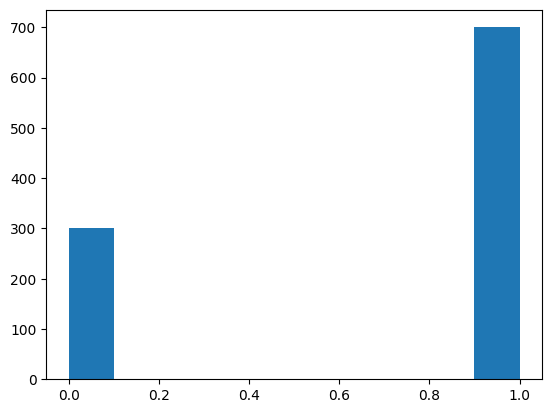

In [7]:
plt.hist(Y)
plt.show()

#Preparation de l'apprentissage

In [8]:
from sklearn.model_selection import train_test_split
#Importation des algorithmes 
from sklearn.tree import DecisionTreeClassifier #Arbre de decision
#Importation de Matrice de confusion 
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score

In [9]:
Xtrain,Xtest,Ytrain,Ytest=train_test_split(X,Y,test_size=0.25,random_state=1)
#La base de test contiendra 25% des indiviuds de la base totale.

In [10]:
Xtest.shape

(250, 9)

#Apprentissage DecisionTreeClassifier

In [13]:
DT=DecisionTreeClassifier(random_state=0, criterion='gini') 


DT.fit(Xtrain,Ytrain) #Apprentissage


YDT=DT.predict(Xtest)#Prediction des clients 

print('Accuracy = {0:.3f}'.format(accuracy_score(Ytest,YDT)))
print('Recall = {0:.3f}'.format(recall_score(Ytest,YDT)))
print('Precision = {0:.3f}'.format(precision_score(Ytest,YDT)))



print('Confusion matrix')
print(confusion_matrix(Ytest, YDT))

Accuracy = 0.696
Recall = 0.784
Precision = 0.784
Confusion matrix
[[ 36  38]
 [ 38 138]]


In [14]:
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression(random_state=0)

LR.fit(Xtrain,Ytrain) #Apprentissage


YLR=LR.predict(Xtest)#Prediction des clients 

print('Accuracy = {0:.3f}'.format(accuracy_score(Ytest,YLR)))
print('Recall = {0:.3f}'.format(recall_score(Ytest,YLR)))
print('Precision = {0:.3f}'.format(precision_score(Ytest,YLR)))



print('confusion matrix')
print(confusion_matrix(Ytest, YLR))

Accuracy = 0.740
Recall = 0.886
Precision = 0.776
confusion matrix
[[ 29  45]
 [ 20 156]]


In [15]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(n_estimators=100, random_state=0)
RF.fit(Xtrain,Ytrain) #Apprentissage


YRF=RF.predict(Xtest)#Prediction des clients 

print('Accuracy = {0:.3f}'.format(accuracy_score(Ytest,YRF)))
print('Recall = {0:.3f}'.format(recall_score(Ytest,YRF)))
print('Precision = {0:.3f}'.format(precision_score(Ytest,YRF)))



print('Confusion matrix')
print(confusion_matrix(Ytest, YRF))

Accuracy = 0.756
Recall = 0.886
Precision = 0.792
Confusion matrix
[[ 33  41]
 [ 20 156]]


In [16]:
from sklearn.ensemble import GradientBoostingClassifier
GB = GradientBoostingClassifier(n_estimators=100, random_state=0)
GB.fit(Xtrain,Ytrain) #Apprentissage


YGB=GB.predict(Xtest)#Prediction des clients 

print('Accuracy = {0:.3f}'.format(accuracy_score(Ytest,YGB)))
print('Recall = {0:.3f}'.format(recall_score(Ytest,YGB)))
print('Precision = {0:.3f}'.format(precision_score(Ytest,YGB)))



print('Confusion matrix')
print(confusion_matrix(Ytest, YGB))

Accuracy = 0.744
Recall = 0.881
Precision = 0.783
Confusion matrix
[[ 31  43]
 [ 21 155]]


In [17]:
from sklearn.svm import SVC
SVM = SVC(kernel='rbf', probability=True, random_state=0)
SVM.fit(Xtrain,Ytrain) #Apprentissage


YSVM=SVM.predict(Xtest)#Prediction des clients 

print('Accuracy = {0:.3f}'.format(accuracy_score(Ytest,YSVM)))
print('Recall = {0:.3f}'.format(recall_score(Ytest,YSVM)))
print('Precision = {0:.3f}'.format(precision_score(Ytest,YSVM)))



print('Confusion matrix')
print(confusion_matrix(Ytest, YSVM))


Accuracy = 0.708
Recall = 0.983
Precision = 0.712
Confusion matrix
[[  4  70]
 [  3 173]]


In [18]:
data={'Age': [67], 'Sex': ['male'],'Job': [2] , 'Housing' : ['own'],'Saving_accounts' : ['NaN'] , 'Checking_account' : ['little'] , 'Credit_amount' : [1169] , 'Duration' : [6] , 'Purpose' : ['radio/TV']}  
df = pd.DataFrame(data)

In [19]:
x_test=trans(df,True)
print(x_test)
#x_test.reshape(-1,1)

YYDT=DT.predict(x_test)
print(YYDT)
joblib.dump(DT, 'model.pkl')

[[  67    0    2    0    0    0 1169    6    0]]
[1]


['model.pkl']